In [1]:
!pip -q install datasets transformers iterative-stratification unidecode scikit-learn matplotlib seaborn
import re, json, time, random, numpy as np, pandas as pd, torch, torch.nn as nn, transformers
import matplotlib.pyplot as plt
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
ENV = {"torch": torch.__version__, "transformers": transformers.__version__,
       "device": torch.cuda.get_device_name(0) if dev == "cuda" else "cpu"}
print(ENV)

{'torch': '2.11.0+cu130', 'transformers': '5.21.0', 'device': 'Tesla T4'}


In [2]:
from datasets import load_dataset
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit as MSSS

ds = load_dataset("google-research-datasets/go_emotions", "simplified")
names = ds["train"].features["labels"].feature.names      # 28 names, "neutral" is last
EMO = names[:-1]                                           # 27 target emotions
df = pd.concat([ds[s].to_pandas() for s in ["train", "validation", "test"]], ignore_index=True)
print("all comments:", len(df))

def multihot(lbls):
    v = np.zeros(27, dtype=np.float32)
    for l in lbls:
        if l != 27: v[l] = 1              # drop Neutral
    return v
df["y"] = df["labels"].apply(multihot)
df = df[df.y.apply(lambda v: v.sum()) > 0].reset_index(drop=True)   # comments that were Neutral-only disappear
print("after removing Neutral:", len(df))

# custom split: 85% train, remaining 15% halved into val/test (ASSUMPTION - confirm in utils.make_dataframes)
Y = np.stack(df.y.values)
tr, rest = next(MSSS(1, test_size=0.15, random_state=SEED).split(df, Y))
rest_df = df.iloc[rest].reset_index(drop=True); Yr = Y[rest]
va, te = next(MSSS(1, test_size=0.5, random_state=SEED).split(rest_df, Yr))
train, val, test = df.iloc[tr].reset_index(drop=True), rest_df.iloc[va].reset_index(drop=True), rest_df.iloc[te].reset_index(drop=True)

def oversample(d, thr=500):
    Yd = np.stack(d.y.values); rng = np.random.default_rng(SEED); extra = []
    for c in range(27):
        n = int(Yd[:, c].sum())
        if 0 < n < thr:
            extra.append(rng.choice(np.where(Yd[:, c] == 1)[0], thr - n, replace=True))
    return pd.concat([d, d.iloc[np.concatenate(extra)]]).sample(frac=1, random_state=SEED).reset_index(drop=True)

train_before = train.copy()
train = oversample(train)
test_single = test[test.y.apply(lambda v: v.sum()) == 1].reset_index(drop=True)   # paper's single-label test set
print(len(train), len(val), len(test), len(test_single))
print("steps/epoch at batch 64:", len(train) // 64, "(paper reports 463)")

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

all comments: 54263
after removing Neutral: 38242
34144 2874 2870 2326
steps/epoch at batch 64: 533 (paper reports 463)


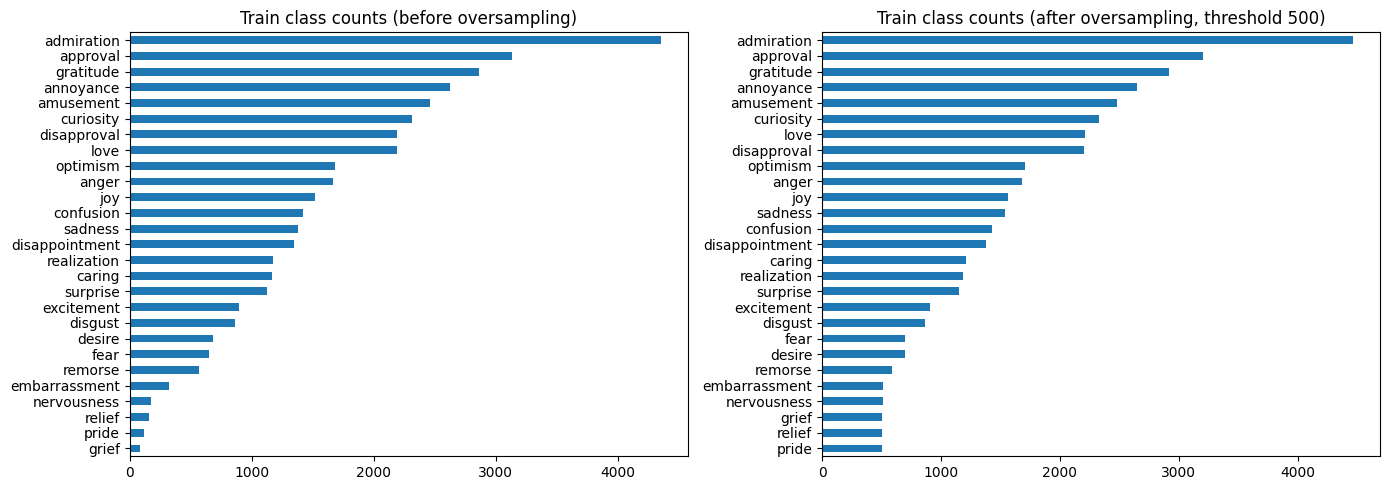

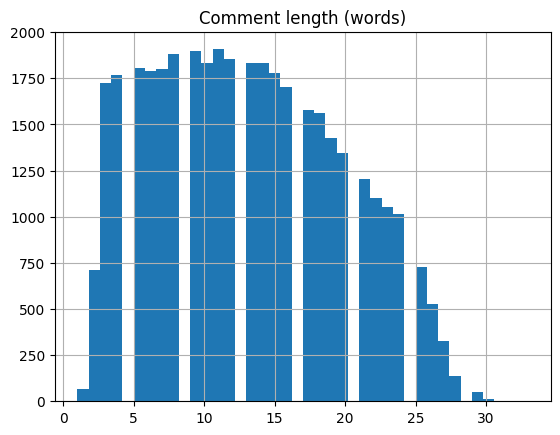

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(np.stack(train_before.y.values).sum(0), index=EMO).sort_values().plot.barh(ax=ax[0], title="Train class counts (before oversampling)")
pd.Series(np.stack(train.y.values).sum(0), index=EMO).sort_values().plot.barh(ax=ax[1], title="Train class counts (after oversampling, threshold 500)")
plt.tight_layout(); plt.savefig("fig_class_distribution.png", dpi=150); plt.show()
df.text.str.split().str.len().hist(bins=40); plt.title("Comment length (words)"); plt.savefig("fig_length.png", dpi=150)

In [18]:
from unidecode import unidecode
CHAT = {"asap": "as soon as possible", "l8r": "later", "r": "are", "u": "you", "@": "at"}  # paper's list is longer
def standardize(t):
    t = unidecode(t)
    t = re.sub(r"\[(NAME|RELIGION)\]", " ", t)
    t = t.lower()
    t = t.replace("can't", "can not").replace("won't", "will not")
    t = re.sub(r"n't\b", " not", t); t = re.sub(r"'re\b", " are", t)
    t = re.sub(r"'ve\b", " have", t); t = re.sub(r"'m\b", " am", t)       # 'll, 's, 'd kept: ambiguous
    t = re.sub(r"([aeiouyshfrm])\1{3,}", r"\1", t)                          # stretched letters
    t = " ".join(CHAT.get(w, w) for w in t.split())
    t = re.sub(r"\w*\d\w*", " ", t)                                         # words containing numbers
    t = re.sub(r"[^a-z\s,.\-'\"!]", " ", t)                                 # keep , . - ' " !
    t = re.sub(r"([,.\-!'\"])\1+", r"\1", t)
    t = re.sub(r"\s*([,.!])\s*", r" \1 ", t)
    return re.sub(r"\s+", " ", t).strip()
for s in [train, val, test, test_single]:
    s["clean"] = s.text.apply(standardize)
print(train[["text", "clean"]].head(5).to_string())

                                                                                                                                                  text                                                                                                                                                  clean
0                                                         I think that’s beautiful, and it looks so easy for whoever has to clean it, no fiddly bits.                                                          i think that's beautiful , and it looks so easy for whoever has to clean it , no fiddly bits .
1                                                                                                 Can they do the same to Tyrael while they are at it?                                                                                                    can they do the same to tyrael while they are at it
2                                   Thanks for the insight. I'm not knowledgeable about it, I 

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Net(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 128, padding_idx=0)
      (position_embeddings): Embedding(512, 128)
      (token_type_embeddings): Embedding(2, 128)
      (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-1): 2 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=128, out_features=128, bias=True)
              (key): Linear(in_features=128, out_features=128, bias=True)
              (value): Linear(in_features=128, out_features=128, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=128, out_features=128, bias=True)
              (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
  

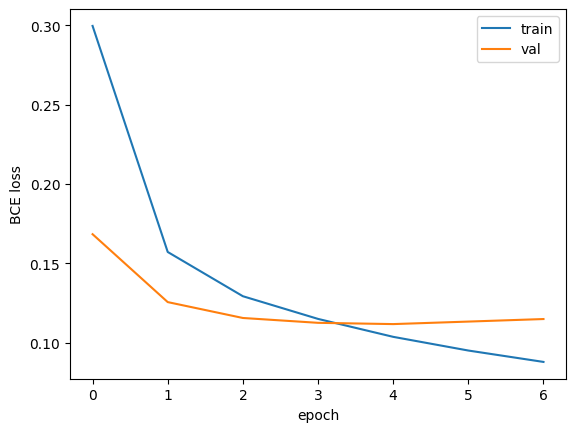

In [19]:
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.utils.data import TensorDataset, DataLoader
CK = "google/bert_uncased_L-2_H-128_A-2"     # Small BERT, L=2, H=128, A=2 (same family as the paper's TF Hub model)
tok = AutoTokenizer.from_pretrained(CK)
def enc(d):
    e = tok(list(d.clean), padding="max_length", truncation=True, max_length=128, return_tensors="pt")
    return TensorDataset(e["input_ids"], e["attention_mask"], torch.tensor(np.stack(d.y.values)))
dl_tr = DataLoader(enc(train), batch_size=64, shuffle=True)
dl_va = DataLoader(enc(val), batch_size=64); dl_te = DataLoader(enc(test), batch_size=64)
dl_ts = DataLoader(enc(test_single), batch_size=64)

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.bert = AutoModel.from_pretrained(CK)
        s.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(128, 256), nn.ReLU(), nn.Dropout(0.4), nn.Linear(256, 27))
    def forward(s, ids, m): return s.head(s.bert(input_ids=ids, attention_mask=m).pooler_output)
model = Net().to(dev); print(model)
print("params:", sum(p.numel() for p in model.parameters()))

CFG = dict(optimizer="AdamW", lr=3e-4, weight_decay=0.01, eps=1e-6, warmup_frac=0.10, batch=64, max_epochs=10,
           patience=2, loss="BCEWithLogits", dropout=0.4, dense=256, max_len=128, threshold=0.5, seed=SEED, oversample_thr=500)
total = CFG["max_epochs"] * len(dl_tr)
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], eps=CFG["eps"])
sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
lossf = nn.BCEWithLogitsLoss()

def run_eval(dl):
    model.eval(); L, P, T = 0, [], []
    with torch.no_grad():
        for ids, m, y in dl:
            o = model(ids.to(dev), m.to(dev)); L += lossf(o, y.to(dev)).item() * len(y)
            P.append(torch.sigmoid(o).cpu().numpy()); T.append(y.numpy())
    return L / len(dl.dataset), np.vstack(P), np.vstack(T)

hist, best, bad, t0 = [], 1e9, 0, time.time()
for ep in range(CFG["max_epochs"]):
    model.train(); tl = 0
    for ids, m, y in dl_tr:
        opt.zero_grad(); l = lossf(model(ids.to(dev), m.to(dev)), y.to(dev)); l.backward(); opt.step(); sch.step(); tl += l.item()
    vl, _, _ = run_eval(dl_va); hist.append((tl / len(dl_tr), vl))
    print(f"epoch {ep+1}: train {hist[-1][0]:.4f}  val {vl:.4f}")
    if vl < best: best, bad = vl, 0; torch.save(model.state_dict(), "baseline_best.pt")
    else:
        bad += 1
        if bad >= CFG["patience"]: print("early stop"); break
CFG["train_seconds"] = round(time.time() - t0); CFG["epochs_run"] = len(hist)
model.load_state_dict(torch.load("baseline_best.pt"))
json.dump({"config": CFG, "env": ENV}, open("baseline_config.json", "w"), indent=2)

plt.plot([h[0] for h in hist], label="train"); plt.plot([h[1] for h in hist], label="val")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.savefig("fig_curves.png", dpi=150)

In [20]:
from sklearn.metrics import precision_recall_fscore_support as prfs, roc_auc_score
def metrics(P, Y, thr=0.5):
    pr = (P >= thr).astype(int); o = {}
    for a in ["micro", "macro", "weighted"]:
        p, r, f, _ = prfs(Y, pr, average=a, zero_division=0); o[a] = (p, r, f)
    o["auc_micro"] = roc_auc_score(Y, P, average="micro"); o["auc_macro"] = roc_auc_score(Y, P, average="macro")
    return o
_, Pv, Yv = run_eval(dl_va); _, Pt, Yt = run_eval(dl_te); _, Ps, Ys = run_eval(dl_ts)
np.save("val_probs.npy", Pv); np.save("val_y.npy", Yv); np.save("test_probs.npy", Pt); np.save("test_y.npy", Yt)  # reused in Assignment 3

POS = ["admiration","amusement","approval","caring","desire","excitement","gratitude","joy","love","optimism","pride","relief"]
NEG = ["anger","annoyance","disappointment","disapproval","disgust","embarrassment","fear","grief","nervousness","remorse","sadness"]
AMB = ["confusion","curiosity","realization","surprise"]
def to_sent(M): return np.stack([M[:, [EMO.index(e) for e in g]].max(1) for g in (POS, NEG, AMB)], 1)

for nm, (P, Yy) in {"single-label test (paper protocol)": (Ps, Ys), "full multi-label test": (Pt, Yt)}.items():
    m = metrics(P, Yy); ms = prfs(to_sent(Yy), to_sent((P >= .5).astype(int)), average="macro", zero_division=0)[2]
    print(nm, {k: np.round(v, 4) for k, v in m.items()}, "sentiment macro-F1:", round(ms, 4))

m = metrics(Ps, Ys)
paper = {"Precision": .61322, "Recall": .55658, "F1 weighted": .56341, "F1 micro": .58353, "F1 macro": .50704, "AUC micro": .9361, "AUC macro": .9136}
mine = {"Precision": m["weighted"][0], "Recall": m["weighted"][1], "F1 weighted": m["weighted"][2], "F1 micro": m["micro"][2],
        "F1 macro": m["macro"][2], "AUC micro": m["auc_micro"], "AUC macro": m["auc_macro"]}
cmp = pd.DataFrame({"Original Paper": paper, "Reproduced": mine}); cmp["Difference"] = cmp.Reproduced - cmp["Original Paper"]
print(cmp.round(4)); cmp.round(4).to_csv("comparison_table.csv")

pc = prfs(Ys, (Ps >= .5).astype(int), average=None, zero_division=0)
per = pd.DataFrame({"precision": pc[0], "recall": pc[1], "f1": pc[2], "support": pc[3]}, index=EMO).round(3)
print(per.loc[["gratitude","excitement","realization","disappointment","nervousness","relief","grief"]]); per.to_csv("per_class.csv")

single-label test (paper protocol) {'micro': array([0.6562, 0.4569, 0.5387]), 'macro': array([0.4696, 0.3646, 0.3861]), 'weighted': array([0.5534, 0.4569, 0.4759]), 'auc_micro': np.float64(0.9223), 'auc_macro': np.float64(0.8841)} sentiment macro-F1: 0.6159
full multi-label test {'micro': array([0.6562, 0.4569, 0.5387]), 'macro': array([0.4696, 0.3646, 0.3861]), 'weighted': array([0.5534, 0.4569, 0.4759]), 'auc_micro': np.float64(0.9223), 'auc_macro': np.float64(0.8841)} sentiment macro-F1: 0.6159
             Original Paper  Reproduced  Difference
Precision            0.6132      0.5534     -0.0599
Recall               0.5566      0.4569     -0.0997
F1 weighted          0.5634      0.4759     -0.0875
F1 micro             0.5835      0.5387     -0.0448
F1 macro             0.5070      0.3861     -0.1209
AUC micro            0.9361      0.9223     -0.0138
AUC macro            0.9136      0.8841     -0.0295
                precision  recall     f1  support
gratitude           0.902   0.9

In [21]:
mine = {"Precision": m["micro"][0], "Recall": m["micro"][1], "F1 weighted": m["weighted"][2],}

In [22]:
def train_run(tag):
    torch.manual_seed(SEED)
    global model
    model = Net().to(dev)
    o = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], eps=CFG["eps"])
    s = get_linear_schedule_with_warmup(o, int(0.1 * total), total)
    best, bad = 1e9, 0
    for ep in range(CFG["max_epochs"]):
        model.train()
        for ids, m_, y in dl_tr:
            o.zero_grad(); l = lossf(model(ids.to(dev), m_.to(dev)), y.to(dev)); l.backward(); o.step(); s.step()
        vl, _, _ = run_eval(dl_va); print(tag, "epoch", ep + 1, "val", round(vl, 4))
        torch.save(model.state_dict(), f"{tag}_last.pt")
        if vl < best: best, bad = vl, 0; torch.save(model.state_dict(), f"{tag}_best.pt")
        else:
            bad += 1
            if bad >= CFG["patience"]: break

def eval_state(path, tag):
    model.load_state_dict(torch.load(path))
    _, Pv_, Yv_ = run_eval(dl_va); _, Ps_, Ys_ = run_eval(dl_ts)
    vm = prfs(Yv_, (Pv_ >= .5).astype(int), average="macro", zero_division=0)[2]
    m_ = metrics(Ps_, Ys_); pc_ = prfs(Ys_, (Ps_ >= .5).astype(int), average=None, zero_division=0)
    print(tag, "| val macro-F1", round(vm, 4), "| test P/R micro", np.round(m_["micro"][:2], 4),
          "F1 micro/macro/weighted", round(m_["micro"][2], 4), round(m_["macro"][2], 4), round(m_["weighted"][2], 4),
          "| zero-F1 classes:", [EMO[i] for i in np.where(pc_[2] == 0)[0]])

train_run("run2")
eval_state("run2_best.pt", "run2 best-val epoch")
eval_state("run2_last.pt", "run2 last epoch")

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run2 epoch 1 val 0.171
run2 epoch 2 val 0.1236
run2 epoch 3 val 0.1136
run2 epoch 4 val 0.1117
run2 epoch 5 val 0.1104
run2 epoch 6 val 0.1126
run2 epoch 7 val 0.1147
run2 best-val epoch | val macro-F1 0.3862 | test P/R micro [0.636  0.4811] F1 micro/macro/weighted 0.5478 0.409 0.4935 | zero-F1 classes: ['disappointment', 'excitement', 'realization']
run2 last epoch | val macro-F1 0.4327 | test P/R micro [0.5989 0.5062] F1 micro/macro/weighted 0.5487 0.4368 0.5176 | zero-F1 classes: []


In [23]:
model.load_state_dict(torch.load("run2_last.pt"))
_, Pv, Yv = run_eval(dl_va); _, Pt, Yt = run_eval(dl_te); _, Ps, Ys = run_eval(dl_ts)
np.save("val_probs_final.npy", Pv); np.save("val_y_final.npy", Yv)
np.save("test_probs_final.npy", Pt); np.save("test_y_final.npy", Yt)
torch.save(model.state_dict(), "baseline_final.pt")

m = metrics(Ps, Ys)
paper = {"Precision (micro)": .61322, "Recall (micro)": .55658, "F1 weighted": .56341,
         "F1 micro": .58353, "F1 macro": .50704, "AUC micro": .9361, "AUC macro": .9136}
mine = {"Precision (micro)": m["micro"][0], "Recall (micro)": m["micro"][1], "F1 weighted": m["weighted"][2],
        "F1 micro": m["micro"][2], "F1 macro": m["macro"][2], "AUC micro": m["auc_micro"], "AUC macro": m["auc_macro"]}
cmp = pd.DataFrame({"Original Paper": paper, "Reproduced": mine})
cmp["Difference"] = cmp["Reproduced"] - cmp["Original Paper"]
print(cmp.round(4)); cmp.round(4).to_csv("comparison_table_final.csv")

pc = prfs(Ys, (Ps >= .5).astype(int), average=None, zero_division=0)
per = pd.DataFrame({"precision": pc[0], "recall": pc[1], "f1": pc[2], "support": pc[3]}, index=EMO).round(3)
print(per); per.to_csv("per_class_final.csv")
print("zero-F1 classes:", per.index[per.f1 == 0].tolist())

mf = metrics(Pt, Yt)
print("full multi-label test: P/R micro", np.round(mf["micro"][:2], 4), "F1 micro/macro/weighted",
      round(mf["micro"][2], 4), round(mf["macro"][2], 4), round(mf["weighted"][2], 4),
      "AUC micro/macro", round(mf["auc_micro"], 4), round(mf["auc_macro"], 4))

CFG["final_model"] = "run2_last.pt: last epoch (6) before early stopping"
json.dump({"config": CFG, "env": ENV}, open("baseline_config.json", "w"), indent=2)

                   Original Paper  Reproduced  Difference
Precision (micro)          0.6132      0.5989     -0.0143
Recall (micro)             0.5566      0.5062     -0.0504
F1 weighted                0.5634      0.5176     -0.0458
F1 micro                   0.5835      0.5487     -0.0349
F1 macro                   0.5070      0.4368     -0.0702
AUC micro                  0.9361      0.9211     -0.0150
AUC macro                  0.9136      0.8832     -0.0304
                precision  recall     f1  support
admiration          0.670   0.712  0.690      524
amusement           0.743   0.881  0.806      318
anger               0.496   0.612  0.548      201
annoyance           0.306   0.250  0.275      296
approval            0.444   0.338  0.384      391
caring              0.519   0.207  0.296      135
confusion           0.448   0.172  0.249      174
curiosity           0.520   0.470  0.493      281
desire              0.667   0.354  0.463       79
disappointment      0.550   0.076  0

In [24]:
import os
from os import listdir
from os.path import join
os.makedirs("goemo", exist_ok=True)
base = "https://raw.githubusercontent.com/google-research/google-research/master/goemotions/data/"
for f in ["train.tsv", "dev.tsv", "test.tsv"]:
    !wget -q -O goemo/{f} {base}{f}

EMO = ["admiration","amusement","anger","annoyance","approval","caring","confusion","curiosity","desire",
       "disappointment","disapproval","disgust","embarrassment","excitement","fear","gratitude","grief","joy",
       "love","nervousness","optimism","pride","realization","relief","remorse","sadness","surprise"]

def load_dfs(d):
    parts = [pd.read_csv(join(d, f), sep="\t", names=["text", "labels", "id"]).drop("id", axis=1)
             for f in sorted(listdir(d)) if f.endswith(".tsv")]
    return pd.concat(parts, axis=0, ignore_index=True)

def drop_labels(df, labels):
    drop = [str(l) for l in labels]
    df["labels"] = df["labels"].str.split(",").map(lambda r: ",".join(x for x in r if x not in drop))
    df.drop(df[df["labels"] == ""].index, axis=0, inplace=True)

def oversample(df, threshold, random=None):
    df = df.copy()
    single = ~df["labels"].str.contains(",")
    counts = df.loc[single, "labels"].value_counts()
    recombined = []
    for label in counts[counts < threshold].index.tolist():
        mask = df["labels"].str.contains(f"(^|,){label}(,|$)", regex=True)
        cdf = df[mask]
        df.drop(cdf.index, axis=0, inplace=True)
        recombined.append(cdf.sample(n=threshold, replace=True, random_state=random))
    return pd.concat([df] + recombined, axis=0, ignore_index=True)

def split_by_class(full_df, fraction, random):          # authors' split_by_class=True, test_only_singles=True
    tr, va, te = [], [], []
    for label, cdf in full_df.groupby("labels"):
        t = cdf.sample(frac=fraction, random_state=random)
        if "," in label:                                  # multi-label: remainder -> validation only
            va.append(cdf.drop(t.index))
        else:                                             # single-label: remainder -> test, 15% of train -> val
            te.append(cdf.drop(t.index))
            v = t.sample(frac=1 - fraction, random_state=random)
            va.append(v); t = t.drop(v.index)
        tr.append(t)
    return [pd.concat(x, axis=0, ignore_index=True) for x in (tr, va, te)]

full = load_dfs("goemo"); print("all comments:", len(full))
drop_labels(full, [27]); print("after removing Neutral:", len(full))
tr_df, va_df, te_df = split_by_class(full, 0.85, SEED)
tr_over = oversample(tr_df, 500, SEED).sample(frac=1, random_state=SEED).reset_index(drop=True)

def conv(d):
    d = d.reset_index(drop=True).copy()
    def mh(s):
        v = np.zeros(27, dtype=np.float32)
        for i in s.split(","): v[int(i)] = 1
        return v
    d["y"] = d["labels"].apply(mh)
    return d[["text", "y"]]
train_before, train, val, test = conv(tr_df), conv(tr_over), conv(va_df), conv(te_df)
test_single = test.copy()          # authors' test set is single-label by construction
print(len(train_before), len(train), len(val), len(test))
print("steps/epoch at batch 64:", len(train) // 64, "(paper reports 463)")

all comments: 54263
after removing Neutral: 38242


/tmp/ipykernel_1490/1850493981.py:29: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df["labels"].str.contains(f"(^|,){label}(,|$)", regex=True)


28607 29620 4969 4666
steps/epoch at batch 64: 462 (paper reports 463)


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train 0.3050  val 0.1710
epoch 2: train 0.1576  val 0.1236
epoch 3: train 0.1267  val 0.1136
epoch 4: train 0.1121  val 0.1117
epoch 5: train 0.1011  val 0.1104
epoch 6: train 0.0923  val 0.1126
epoch 7: train 0.0858  val 0.1147
early stop
validation macro-F1: {'authors_split_best.pt': 0.3863729626305918, 'authors_split_last.pt': 0.4311348090273308}
final checkpoint: authors_split_last.pt
                   Original Paper  Reproduced  Difference
Precision (micro)          0.6132      0.5966     -0.0167
Recall (micro)             0.5566      0.5064     -0.0502
F1 weighted                0.5634      0.5167     -0.0467
F1 micro                   0.5835      0.5478     -0.0357
F1 macro                   0.5070      0.4374     -0.0697
AUC micro                  0.9361      0.9211     -0.0150
AUC macro                  0.9136      0.8833     -0.0303
                precision  recall     f1  support
admiration          0.670   0.714  0.691      524
amusement           0.736   0.877  

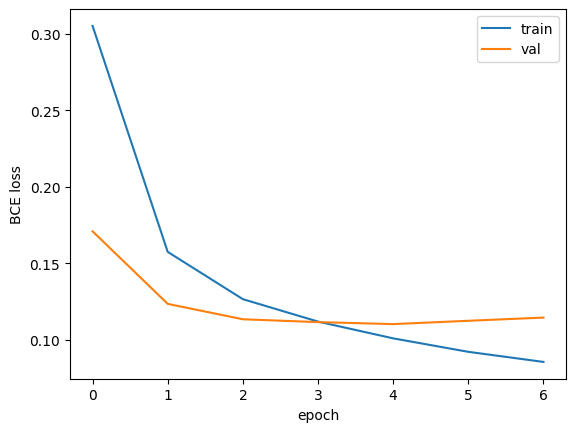

In [28]:
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support as prfs, roc_auc_score
CK = "google/bert_uncased_L-2_H-128_A-2"
tok = AutoTokenizer.from_pretrained(CK)

def enc(d):
    # Ensure the 'clean' column exists; if not, apply the standardize function
    texts = list(d.clean) if "clean" in d.columns else list(d.text.apply(standardize))
    e = tok(texts, padding="max_length", truncation=True, max_length=128, return_tensors="pt")
    return TensorDataset(e["input_ids"], e["attention_mask"], torch.tensor(np.stack(d.y.values)))

dl_tr = DataLoader(enc(train), batch_size=64, shuffle=True)
dl_va, dl_te = DataLoader(enc(val), batch_size=64), DataLoader(enc(test), batch_size=64)

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.bert = AutoModel.from_pretrained(CK)
        s.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(128, 256), nn.ReLU(), nn.Dropout(0.4), nn.Linear(256, 27))
    def forward(s, ids, m): return s.head(s.bert(input_ids=ids, attention_mask=m).pooler_output)

CFG = dict(optimizer="AdamW", lr=3e-4, weight_decay=0.01, eps=1e-6, warmup_frac=0.10, batch=64, max_epochs=10,
           patience=2, loss="BCEWithLogits", dropout=0.4, dense=256, max_len=128, threshold=0.5, seed=SEED, oversample_thr=500)
total = CFG["max_epochs"] * len(dl_tr)
lossf = nn.BCEWithLogitsLoss()

def run_eval(dl):
    model.eval(); L, P, T = 0, [], []
    with torch.no_grad():
        for ids, m_, y in dl:
            o = model(ids.to(dev), m_.to(dev)); L += lossf(o, y.to(dev)).item() * len(y)
            P.append(torch.sigmoid(o).cpu().numpy()); T.append(y.numpy())
    return L / len(dl.dataset), np.vstack(P), np.vstack(T)

def metrics(P, Y, thr=0.5):
    pr = (P >= thr).astype(int); o = {}
    for a in ["micro", "macro", "weighted"]:
        p, r, f, _ = prfs(Y, pr, average=a, zero_division=0); o[a] = (p, r, f)
    o["auc_micro"] = roc_auc_score(Y, P, average="micro"); o["auc_macro"] = roc_auc_score(Y, P, average="macro")
    return o

def train_run(tag):
    global model
    torch.manual_seed(SEED); model = Net().to(dev)
    o = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], eps=CFG["eps"])
    s = get_linear_schedule_with_warmup(o, int(0.1 * total), total)
    best, bad, hist, t0 = 1e9, 0, [], time.time()
    for ep in range(CFG["max_epochs"]):
        model.train(); tl = 0
        for ids, m_, y in dl_tr:
            o.zero_grad(); l = lossf(model(ids.to(dev), m_.to(dev)), y.to(dev)); l.backward(); o.step(); s.step(); tl += l.item()
        vl, _, _ = run_eval(dl_va); hist.append((tl / len(dl_tr), vl))
        print(f"epoch {ep+1}: train {hist[-1][0]:.4f}  val {vl:.4f}")
        torch.save(model.state_dict(), f"{tag}_last.pt")
        if vl < best: best, bad = vl, 0; torch.save(model.state_dict(), f"{tag}_best.pt")
        else:
            bad += 1
            if bad >= CFG["patience"]: print("early stop"); break
    return hist, round(time.time() - t0)

hist, secs = train_run("authors_split")
CFG["train_seconds"], CFG["epochs_run"] = secs, len(hist)
plt.figure(); plt.plot([h[0] for h in hist], label="train"); plt.plot([h[1] for h in hist], label="val")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.savefig("fig_curves.png", dpi=150)

def val_macro(path):
    model.load_state_dict(torch.load(path)); _, Pv_, Yv_ = run_eval(dl_va)
    return prfs(Yv_, (Pv_ >= .5).astype(int), average="macro", zero_division=0)[2]
vm = {p: val_macro(p) for p in ["authors_split_best.pt", "authors_split_last.pt"]}
print("validation macro-F1:", vm)
final = max(vm, key=vm.get); print("final checkpoint:", final)
model.load_state_dict(torch.load(final)); torch.save(model.state_dict(), "baseline_final.pt")
CFG["final_model"] = f"{final} (chosen by validation macro-F1)"
json.dump({"config": CFG, "env": ENV}, open("baseline_config.json", "w"), indent=2)

_, Pv, Yv = run_eval(dl_va); _, Pt, Yt = run_eval(dl_te)
np.save("val_probs_final.npy", Pv); np.save("val_y_final.npy", Yv); np.save("test_probs_final.npy", Pt); np.save("test_y_final.npy", Yt)
m = metrics(Pt, Yt)
paper = {"Precision (micro)": .61322, "Recall (micro)": .55658, "F1 weighted": .56341,
         "F1 micro": .58353, "F1 macro": .50704, "AUC micro": .9361, "AUC macro": .9136}
mine = {"Precision (micro)": m["micro"][0], "Recall (micro)": m["micro"][1], "F1 weighted": m["weighted"][2],
        "F1 micro": m["micro"][2], "F1 macro": m["macro"][2], "AUC micro": m["auc_micro"], "AUC macro": m["auc_macro"]}
cmp = pd.DataFrame({"Original Paper": paper, "Reproduced": mine}); cmp["Difference"] = cmp["Reproduced"] - cmp["Original Paper"]
print(cmp.round(4)); cmp.round(4).to_csv("comparison_table_final.csv")
pc = prfs(Yt, (Pt >= .5).astype(int), average=None, zero_division=0)
per = pd.DataFrame({"precision": pc[0], "recall": pc[1], "f1": pc[2], "support": pc[3]}, index=EMO).round(3)
print(per); per.to_csv("per_class_final.csv"); print("zero-F1 classes:", per.index[per.f1 == 0].tolist())

In [27]:
from unidecode import unidecode
CHAT = {"asap": "as soon as possible", "l8r": "later", "r": "are", "u": "you", "@": "at"}
def standardize(t):
    t = unidecode(t)
    t = re.sub(r"\[(NAME|RELIGION)\]", " ", t)
    t = t.lower()
    t = t.replace("can't", "can not").replace("won't", "will not")
    t = re.sub(r"n't\b", " not", t); t = re.sub(r"'re\b", " are", t)
    t = re.sub(r"'ve\b", " have", t); t = re.sub(r"'m\b", " am", t)
    t = re.sub(r"([aeiouyshfrm])\1{3,}", r"\1", t)
    t = " ".join(CHAT.get(w, w) for w in t.split())
    t = re.sub(r"\w*\d\w*", " ", t)
    t = re.sub(r"[^a-z\s,.\-'\"!]", " ", t)
    t = re.sub(r"([,.\-!'\"])\1+", r"\1", t)
    t = re.sub(r"\s*([,.!])\s*", r" \1 ", t)
    return re.sub(r"\s+", " ", t).strip()

for s in (train, val, test):
    s["clean"] = s["text"].apply(standardize)

print(train.columns.tolist(), len(train), len(val), len(test))
assert all("clean" in d.columns for d in (train, val, test))
print(train[["text", "clean"]].head(3).to_string())

['text', 'y', 'clean'] 29620 4969 4666
                                                                                                                 text                                                                                                                     clean
0                        I think that’s beautiful, and it looks so easy for whoever has to clean it, no fiddly bits.                             i think that's beautiful , and it looks so easy for whoever has to clean it , no fiddly bits .
1                                                                Can they do the same to Tyrael while they are at it?                                                                       can they do the same to tyrael while they are at it
2  Thanks for the insight. I'm not knowledgeable about it, I admit. I am sensitive to many types of plastics, though.  thanks for the insight . i am not knowledgeable about it , i admit . i am sensitive to many types of plastics , though .


In [29]:
print("train seconds:", CFG["train_seconds"], "| epochs:", CFG["epochs_run"])
_m = Net(); print(_m); print("params:", sum(p.numel() for p in _m.parameters()))


train seconds: 60 | epochs: 7


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Net(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 128, padding_idx=0)
      (position_embeddings): Embedding(512, 128)
      (token_type_embeddings): Embedding(2, 128)
      (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-1): 2 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=128, out_features=128, bias=True)
              (key): Linear(in_features=128, out_features=128, bias=True)
              (value): Linear(in_features=128, out_features=128, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=128, out_features=128, bias=True)
              (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
  

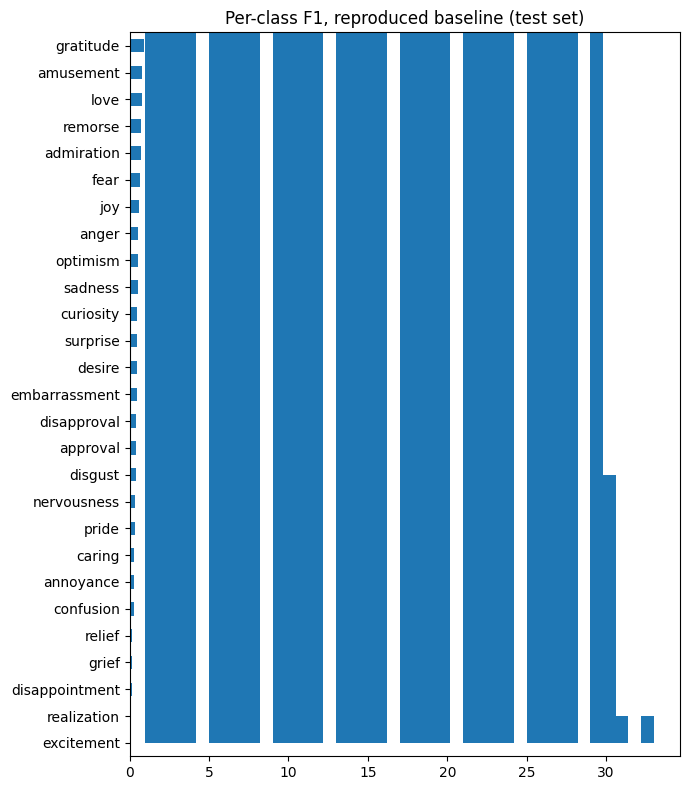

In [30]:
plt.figure(); full.text.str.split().str.len().hist(bins=40); plt.title("Comment length (words)"); plt.savefig("fig_length.png", dpi=150)
per = pd.read_csv("per_class_final.csv", index_col=0)
per["f1"].sort_values().plot.barh(figsize=(7, 8), title="Per-class F1, reproduced baseline (test set)")
plt.tight_layout(); plt.savefig("fig_per_class_f1.png", dpi=150)

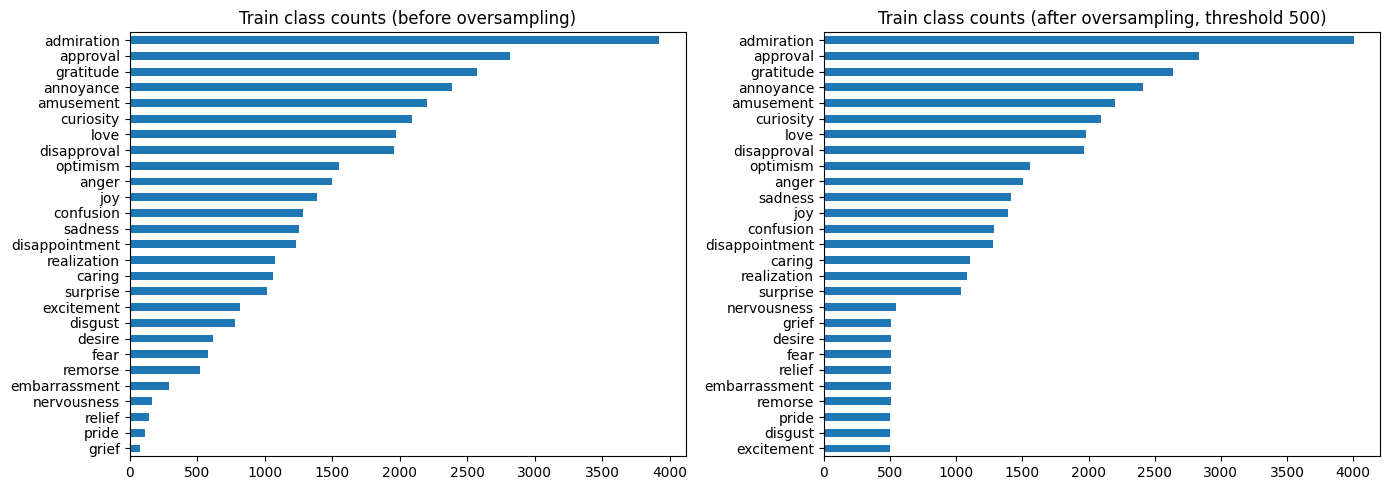

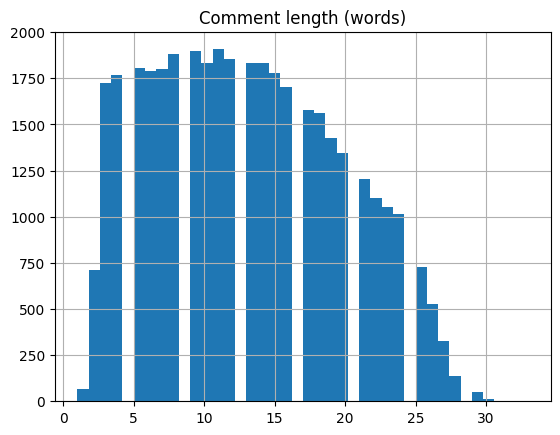

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(np.stack(train_before.y.values).sum(0), index=EMO).sort_values().plot.barh(ax=ax[0], title="Train class counts (before oversampling)")
pd.Series(np.stack(train.y.values).sum(0), index=EMO).sort_values().plot.barh(ax=ax[1], title="Train class counts (after oversampling, threshold 500)")
plt.tight_layout(); plt.savefig("fig_class_distribution.png", dpi=150); plt.show()
df.text.str.split().str.len().hist(bins=40); plt.title("Comment length (words)"); plt.savefig("fig_length.png", dpi=150)